# Entrega 02 · Exploración de los datos (EDA)

Este notebook **no transforma** nada: lee el Gold que genera `src/pipeline.py` y resume qué hay en los datos,
para respaldar las cifras del documento `docs/entregas/02_datos_y_preparacion.md`.
No se muestra ningún texto de reseña (privacidad).

**Cómo reproducirlo:** (1) ejecutar `python src/pipeline.py` para generar `data/reviews.db`; (2) abrir este notebook.
En Google Colab, si no encuentra la base de datos, la pedirá como fichero a subir.

In [1]:
import os, sqlite3
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 3.5), "axes.spines.top": False, "axes.spines.right": False})


DB_PATH = next((p for p in ("data/reviews.db", "../data/reviews.db") if os.path.exists(p)), None)
if DB_PATH is None:
    from google.colab import files
    os.makedirs("data", exist_ok=True)
    up = files.upload()                      # selecciona reviews.db
    DB_PATH = "data/reviews.db"
    os.replace(list(up.keys())[0], DB_PATH)

con = sqlite3.connect(DB_PATH)
print("Tablas:", [r[0] for r in con.execute("select name from sqlite_master where type='table'")])
gold = pd.read_sql("select * from gold_reviews", con)
hold = pd.read_sql("select * from holdout_reviews", con)
print(f"Gold: {len(gold)} reseñas | columnas: {list(gold.columns)}")

Saving reviews.db to reviews.db
Tablas: ['silver_reviews', 'gold_reviews', 'holdout_reviews']
Gold: 855 reseñas | columnas: ['review_id', 'created_at', 'year', 'rating', 'text', 'has_text', 'n_chars', 'lang', 'has_reply', 'reply_text']


## 1. Visión general

In [2]:
tot = len(gold)
con_texto = int(gold.has_text.sum())
resumen = pd.Series({
    "Reseñas totales": tot,
    "Periodo": f"{gold.created_at.min()[:4]}-{gold.created_at.max()[:4]}",
    "Con texto": f"{con_texto} ({con_texto/tot:.0%})",
    "Sin texto (solo estrellas)": f"{tot-con_texto} ({(tot-con_texto)/tot:.0%})",
    "Con respuesta del propietario": int(gold.has_reply.sum()),
    "Valoración media": round(gold.rating.mean(), 2),
})
resumen.to_frame("valor")

,valor
Reseñas totales,855
Periodo,2011-2026
Con texto,438 (51%)
Sin texto (solo estrellas),417 (49%)
Con respuesta del propietario,2
Valoración media,4.44


## 2. Valoraciones: ¿cuántas críticas hay?
Las críticas (1-2★) son lo que el producto debe detectar, y son las menos frecuentes.

,todas,con texto
estrellas,,
1,36,20
2,22,15
3,38,14
4,189,78
5,570,311


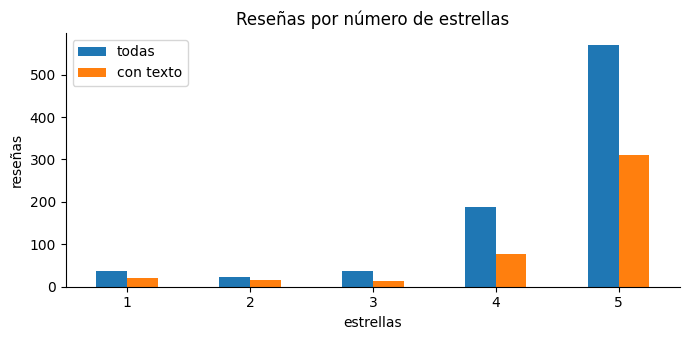

Con texto: 438 | críticas (1-2★): 35 | neutras (3★): 14 | positivas (4-5★): 389


In [3]:
est = pd.DataFrame({
    "todas": gold.rating.value_counts().sort_index(),
    "con texto": gold[gold.has_text == 1].rating.value_counts().sort_index(),
}).fillna(0).astype(int)
est.index.name = "estrellas"
display(est)

ax = est.plot.bar(rot=0)
ax.set_title("Reseñas por número de estrellas"); ax.set_ylabel("reseñas"); plt.tight_layout(); plt.show()

t = gold[gold.has_text == 1]
print(f"Con texto: {len(t)} | críticas (1-2★): {(t.rating <= 2).sum()} | "
      f"neutras (3★): {(t.rating == 3).sum()} | positivas (4-5★): {(t.rating >= 4).sum()}")

## 3. Evolución en el tiempo
El volumen cambia mucho con los años: condiciona cómo se debe evaluar un modelo (la deriva temporal).

year,2011,2013,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
reseñas,1,1,1,15,65,128,155,127,140,74,62,43,29,14
con_texto,0,0,1,9,34,53,69,60,76,44,35,28,19,10


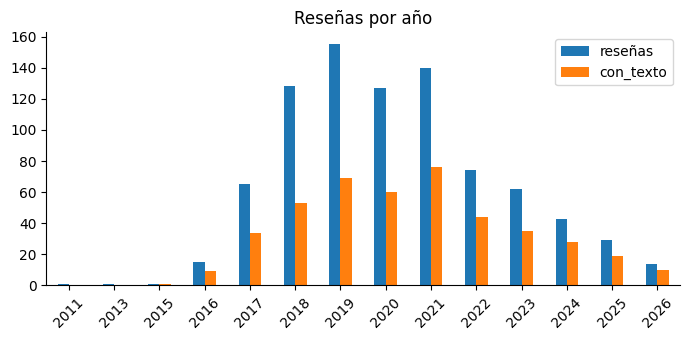

In [4]:
por_anio = gold.groupby("year").agg(reseñas=("review_id", "size"), con_texto=("has_text", "sum"))
display(por_anio.T)
ax = por_anio.plot.bar(rot=45)
ax.set_title("Reseñas por año"); ax.set_xlabel(""); plt.tight_layout(); plt.show()

## 4. Longitud del texto
Las críticas tienden a ser más largas que las reseñas positivas.

                 count  median  mean
grupo                               
crítica (1-2★)      35     290   343
mixta (3★)          14     102   191
positiva (4-5★)    389      86   136


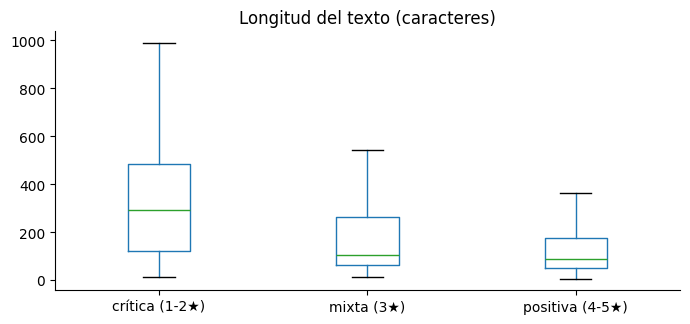

In [5]:
t = gold[gold.has_text == 1].copy()
t["grupo"] = pd.cut(t.rating, [0, 2, 3, 5], labels=["crítica (1-2★)", "mixta (3★)", "positiva (4-5★)"])
print(t.groupby("grupo", observed=True).n_chars.agg(["count", "median", "mean"]).round(0).astype(int))
ax = t.boxplot(column="n_chars", by="grupo", grid=False, showfliers=False)
ax.set_title("Longitud del texto (caracteres)"); plt.suptitle(""); ax.set_xlabel(""); plt.tight_layout(); plt.show()

## 5. Idioma
La detección automática es poco fiable en textos muy cortos (por eso hay valores vacíos).

In [6]:
print(gold[gold.has_text == 1].lang.value_counts(dropna=False).rename_axis("idioma").to_frame("reseñas"))

        reseñas
idioma         
es          398
None         25
pt            6
it            2
en            2
ca            1
so            1
fr            1
cy            1
de            1


## 6. Conjunto reservado (hold-out)
Reserva fija del 25% de las reseñas con texto, con críticas garantizadas (ver apartado 4 del documento).
Se comprueba que se parece al conjunto completo.

In [7]:
m = hold.merge(gold, on="review_id")
print(f"Reservadas: {len(m)} | críticas (≤3★): {(m.stratum == 'critica').sum()} | resto: {(m.stratum == 'resto').sum()}")

comp = pd.DataFrame({
    "Gold con texto (%)": (gold[gold.has_text == 1].rating.value_counts(normalize=True).sort_index() * 100).round(1),
    "Hold-out (%)": (m.rating.value_counts(normalize=True).sort_index() * 100).round(1),
})
comp.index.name = "estrellas"
display(comp)

assert set(hold.review_id) <= set(gold[gold.has_text == 1].review_id), "El hold-out contiene reseñas sin texto"
assert hold.review_id.is_unique
print("Comprobaciones OK: todas tienen texto y no hay duplicados.")

Reservadas: 109 | críticas (≤3★): 12 | resto: 97


,Gold con texto (%),Hold-out (%)
estrellas,,
1,4.6,5.5
2,3.4,3.7
3,3.2,1.8
4,17.8,24.8
5,71.0,64.2


Comprobaciones OK: todas tienen texto y no hay duplicados.


## Conclusiones del EDA
- Hay **855 reseñas reales**, pero solo **la mitad tiene texto** utilizable para analizar lenguaje.
- Las **críticas son pocas** (35 con 1-2★ y texto): es la limitación principal y condiciona cómo se evaluará un modelo.
- Solo hay **2 respuestas del propietario**: no sirven como corpus; las respuestas se resolverán con plantillas acordadas con la familia.
- El volumen **baja desde 2022**, así que un split aleatorio mezclaría épocas distintas.
- El conjunto reservado mantiene un reparto de estrellas parecido al total y garantiza ejemplos críticos.